# Task 1 — Dataset and Poker Environment

**Owner:** Ganesh · **Project:** Learning card replacement strategies in five-card draw with tabular Q-learning

This notebook covers Task 1:

1. Load and validate the UCI Poker Hand dataset, and check the data claims in the proposal.
2. Deduplicate the data and create the shared **train / dev / eval** split.
3. Implement and verify hand scoring and canonicalization, including the card-position mapping.
4. Implement replacement draws without replacement from the 47 cards outside the original hand.
5. Write the report material on data processing and the poker environment (§8).

The reusable code lives in two modules that the other tasks import:

| File | Contents |
|---|---|
| `poker_env.py` | card encoding, hand evaluator, payouts, canonicalization + mask mapping, draw simulator, exact EV calculator |
| `poker_data.py` | UCI loading, deduplication, split construction, `load_split(name)` |
| `CONVENTIONS.md` | proposed shared conventions (card/action encoding, interfaces, split, seeds) |
| `test_poker_env.py` | standalone unit tests (`python test_poker_env.py`) |
| `data/splits/*.npz` | the shared splits, plus `manifest.json` |

In [1]:
import json, time
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import poker_env as pe
import poker_data as pdata

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
pd.set_option("display.width", 140)

## 0. Conventions used by this environment

Full list in `CONVENTIONS.md`. In brief:

* **Card:** `card = 4*rank + suit`, with rank 0..12 = 2..A and suit 0..3 = h, s, d, c (same suit order as UCI). Sorting card ints sorts by rank and then suit.
* **Hand:** 5 distinct card ints. Position *i* is UCI card *i+1*, and the simulator never reorders positions.
* **Action:** a 5-bit mask from 0 to 31. Bit *i* (`1 << i`) is position *i*, and **1 = keep**, so `31` keeps all cards and `0` discards all of them.
* **Canonicalization:** `canonicalize(hand) -> (canon_hand, perm, state_id)`, where `canon_hand[j]` comes from original position `perm[j]`. A mask chosen on the canonical hand maps back with `canonical_mask_to_original(mask, perm)` (bit *j* → bit `perm[j]`).
* **Interfaces:** `policy(hand) -> mask`, `simulate_draw(hand, mask, rng) -> final_hand`, `payout(final_hand, paytable) -> float`.

In [2]:
h = pe.parse_hand("Kh 7c Ks 2d Jh")
print("hand:", pe.hand_to_str(h), "->", h.tolist())
m = pe.mask_from_keep([0, 2])          # keep the two kings
print("mask:", m, f"= {m:05b} (bit 0 is rightmost) =", pe.mask_to_str(m), "(position 0 first)")
print("UCI encoding round-trip:", [tuple(map(int, x)) for x in zip(*pe.cards_to_uci(h))])

hand: Kh 7c Ks 2d Jh -> [44, 23, 45, 2, 36]
mask: 5 = 00101 (bit 0 is rightmost) = KDKDD (position 0 first)
UCI encoding round-trip: [(1, 13), (4, 7), (2, 13), (3, 2), (1, 11)]


## 1. Load and validate the raw UCI files

The two files from `poker+hand.zip` are extracted to `data/raw/`. Each row holds 5 × (suit S ∈ 1..4, rank C ∈ 1..13 with 1 = Ace) plus CLASS ∈ 0..9.

In [3]:
raw = {"train file": pdata.load_uci(pdata.TRAIN_FILE), "test file": pdata.load_uci(pdata.TEST_FILE)}
cards = {k: pdata.df_to_cards(v) for k, v in raw.items()}

rows = []
for name, df in raw.items():
    c = np.sort(cards[name], axis=1)
    S = df[["S1","S2","S3","S4","S5"]].to_numpy(); C = df[["C1","C2","C3","C4","C5"]].to_numpy()
    rows.append({
        "file": name, "rows": len(df), "columns": df.shape[1],
        "missing values": int(df.isna().sum().sum()),
        "dtype ok": all(np.issubdtype(t, np.integer) for t in df.dtypes),
        "suits in 1..4": bool(((S >= 1) & (S <= 4)).all()),
        "ranks in 1..13": bool(((C >= 1) & (C <= 13)).all()),
        "CLASS in 0..9": bool(df.CLASS.between(0, 9).all()),
        "hands with a repeated card": int((c[:, 1:] == c[:, :-1]).any(axis=1).sum()),
    })
validation = pd.DataFrame(rows).set_index("file").T
validation

file,train file,test file
rows,25010,1000000
columns,11,11
missing values,0,0
dtype ok,True,True
suits in 1..4,True,True
ranks in 1..13,True,True
CLASS in 0..9,True,True
hands with a repeated card,0,0


### 1.1 Are ranks and suits uniform?

If the hands are uniform random deals, each of the 13 ranks and each of the 4 suits appears equally often across all card slots. Below are chi-square goodness-of-fit tests over all 5 positions, and also for each position separately.

In [4]:
rows = []
for name, df in raw.items():
    for kind, cols, k in [("suit", ["S1","S2","S3","S4","S5"], 4), ("rank", ["C1","C2","C3","C4","C5"], 13)]:
        allv = df[cols].to_numpy().ravel()
        obs = np.bincount(allv, minlength=k + 1)[1:]
        chi2, p = stats.chisquare(obs)
        per_pos_p = [stats.chisquare(np.bincount(df[c], minlength=k + 1)[1:]).pvalue for c in cols]
        rows.append({"file": name, "attribute": kind, "chi2": round(chi2, 2), "dof": k - 1, "p (all slots)": round(p, 3),
                     "min p over 5 slots": round(min(per_pos_p), 3),
                     "max rel. deviation": f"{np.abs(obs / obs.mean() - 1).max():.2%}"})
pd.DataFrame(rows)

,file,attribute,chi2,dof,p (all slots),min p over 5 slots,max rel. deviation
0,train file,suit,1.31,3,0.728,0.093,0.52%
1,train file,rank,9.01,12,0.702,0.200,2.04%
2,test file,suit,7.10,3,0.069,0.110,0.19%
3,test file,rank,6.72,12,0.875,0.035,0.23%


No test rejects uniformity at the 1% level, and in the 1M-row file every suit and rank count is within a fraction of a percent of its expected value.

### 1.2 Does our evaluator reproduce every CLASS label?

`poker_env` scores hands with a vectorized evaluator that fills a lookup table over all 2,598,960 hands. A single hand is scored by computing its combinatorial index and reading the table.

In [5]:
for name, df in raw.items():
    pred = pe.CATEGORY_TO_UCI[pe.hand_category_batch(cards[name])]
    mism = int((pred != df.CLASS.to_numpy()).sum())
    print(f"{name:10s}: {len(df):>9,} hands, mismatches = {mism}")

train file:    25,010 hands, mismatches = 0
test file : 1,000,000 hands, mismatches = 0


## 2. Check the data claims in the proposal

The proposal states class frequencies, oversampling factors, duplicate counts and state counts. Exact class probabilities for a uniform deal come from enumerating all $\binom{52}{5}$ hands with our evaluator. §3 checks that enumeration against the textbook counts.

In [6]:
all_cat = pe._tables()["category_lut"]
true_counts = np.bincount(pe.CATEGORY_TO_UCI[all_cat], minlength=10)
true_p = true_counts / pe.N_HANDS

freq = pd.DataFrame({"class": pe.UCI_CLASS_NAMES, "exact count (of 2,598,960)": true_counts,
                     "exact p": true_p})
for name, df in raw.items():
    cnt = np.bincount(df.CLASS, minlength=10)
    freq[f"{name} count"] = cnt
    freq[f"{name} p"] = cnt / len(df)
    freq[f"{name} ratio to exact"] = (cnt / len(df)) / true_p
freq.style.format({c: "{:.4%}" for c in freq.columns if c.endswith(" p")} |
                  {c: "{:.2f}" for c in freq.columns if "ratio" in c} |
                  {c: "{:,}" for c in freq.columns if "count" in c})

,class,"exact count (of 2,598,960)",exact p,train file count,train file p,train file ratio to exact,test file count,test file p,test file ratio to exact
0,nothing,"1,302,540",50.1177%,"12,493",49.9520%,1.00,"501,209",50.1209%,1.00
1,one_pair,"1,098,240",42.2569%,"10,599",42.3790%,1.00,"422,498",42.2498%,1.00
2,two_pair,"123,552",4.7539%,"1,206",4.8221%,1.01,"47,622",4.7622%,1.00
3,three_of_a_kind,"54,912",2.1128%,513,2.0512%,0.97,"21,121",2.1121%,1.00
4,straight,"10,200",0.3925%,93,0.3719%,0.95,"3,885",0.3885%,0.99
5,flush,"5,108",0.1965%,54,0.2159%,1.10,"1,996",0.1996%,1.02
6,full_house,"3,744",0.1441%,36,0.1439%,1.00,"1,424",0.1424%,0.99
7,four_of_a_kind,624,0.0240%,6,0.0240%,1.00,230,0.0230%,0.96
8,straight_flush,36,0.0014%,5,0.0200%,14.43,12,0.0012%,0.87
9,royal_flush,4,0.0002%,5,0.0200%,129.90,3,0.0003%,1.95


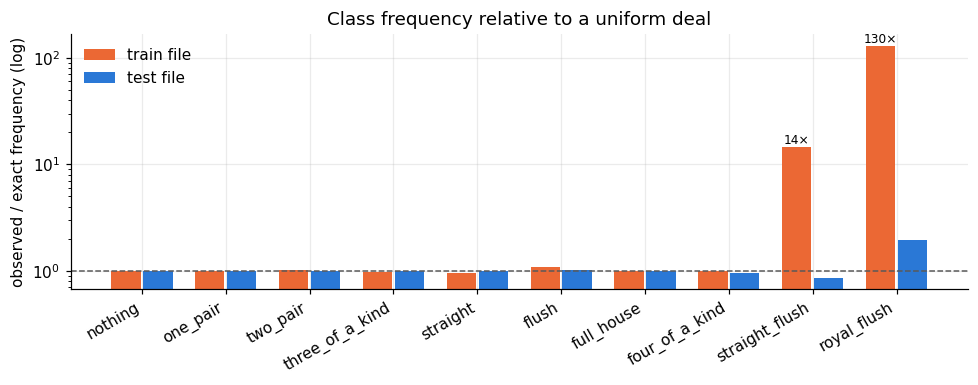

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(10); w = 0.38
for i, (name, color) in enumerate([("train file", ORANGE), ("test file", BLUE)]):
    ax.bar(x + (i - 0.5) * w, freq[f"{name} ratio to exact"], w * 0.92, color=color, label=name)
ax.axhline(1, color="0.35", lw=1, ls="--")
ax.set_yscale("log"); ax.set_xticks(x, pe.UCI_CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("observed / exact frequency (log)")
ax.set_title("Class frequency relative to a uniform deal")
for i in (8, 9):
    ax.annotate(f"{freq.loc[i, 'train file ratio to exact']:.0f}×", (i - w / 2, freq.loc[i, "train file ratio to exact"]),
                ha="center", va="bottom", fontsize=8)
ax.legend(frameon=False); fig.tight_layout(); plt.show()

The 1M-row test file matches a uniform deal in every class that has enough samples to judge. The train file oversamples straight flushes and royal flushes. A chi-square test makes this precise (classes 7 to 9 are merged so that every expected count is at least 5):

In [8]:
def class_gof(counts, p):
    obs = np.r_[counts[:7], counts[7:].sum()]; exp = np.r_[p[:7], p[7:].sum()] * counts.sum()
    return stats.chisquare(obs, exp)
for name, df in raw.items():
    r = class_gof(np.bincount(df.CLASS, minlength=10), true_p)
    print(f"{name:10s}: chi2 = {r.statistic:8.2f}, p = {r.pvalue:.3g}")

train file: chi2 =    16.12, p = 0.024
test file : chi2 =     1.66, p = 0.976


### 2.1 Duplicates and overlap

The records are **order sensitive**: the same 5 cards in a different order count as a different record. For a discard policy only the card *set* matters, so we deduplicate on the unordered set (`pe.hand_index`, a combinatorial index in 0..2,598,959).

In [9]:
keys = {k: pe.hand_index_batch(v) for k, v in cards.items()}
dup_rows = []
for name, df in raw.items():
    exact_rows = len(df) - len(df.drop_duplicates())
    uniq = len(np.unique(keys[name]))
    dup_rows.append({"file": name, "rows": len(df), "identical rows": exact_rows,
                     "unique card sets": uniq, "repeated card sets (rows - unique)": len(df) - uniq})
shared = np.intersect1d(keys["train file"], keys["test file"])
display(pd.DataFrame(dup_rows).set_index("file"))
print(f"card sets present in both files: {len(shared):,}")

,rows,identical rows,unique card sets,repeated card sets (rows - unique)
file,,,,
train file,25010,2,24898,112
test file,1000000,2128,829201,170799


card sets present in both files: 7,849


Most of the duplication only appears after ignoring card order. Only 2,128 test rows are byte-identical, but 170,799 rows repeat a card set seen earlier in the file. This is close to what we expect from sampling ordered hands with replacement: 1M draws from 2.6M sets would give about $2{,}598{,}960\,(1 - e^{-10^6/2{,}598{,}960}) \approx 830{,}100$ unique sets, and we observe 829,201.

In [10]:
n = 1_000_000
print(f"expected unique sets under i.i.d. uniform sampling: {pe.N_HANDS * (1 - (1 - 1 / pe.N_HANDS) ** n):,.0f}")

expected unique sets under i.i.d. uniform sampling: 830,088


### 2.2 Canonical states

Relabeling suits and reordering cards does not change a hand's value or the value of any action, so we merge hands into canonical states (definition in §4). Enumerating all 2,598,960 hands gives the number of states, and from that the share of states each file covers.

In [11]:
n_states = len(pe.canonical_states())
sid = {k: pe.state_id_batch(v) for k, v in cards.items()}
print(f"canonical states by enumeration: {n_states:,}")
for name in raw:
    u = len(np.unique(sid[name]))
    print(f"{name:10s} covers {u:,} states = {u / n_states:.2%}")

canonical states by enumeration: 134,459
train file covers 22,602 states = 16.81%
test file  covers 133,462 states = 99.26%


In [12]:
oversample = freq.loc[[8, 9], "train file ratio to exact"].to_numpy()
claims = pd.DataFrame([
    ("Train file rows", "25,010", f"{len(raw['train file']):,}"),
    ("Test file rows", "1,000,000", f"{len(raw['test file']):,}"),
    ("Missing values", "none", str(int(validation.loc['missing values'].sum()))),
    ("Evaluator reproduces all CLASS labels", "1,025,010 / 1,025,010", "1,025,010 / 1,025,010"),
    ("Repeated cards within a hand", "none", str(int(validation.loc['hands with a repeated card'].sum()))),
    ("Ranks and suits uniform", "yes", "yes (all chi-square p > 0.01)"),
    ("Test file one-pair frequency vs exact", "42.25% vs 42.26%", f"{freq.loc[1,'test file p']:.2%} vs {true_p[1]:.2%}"),
    ("Train file straight-flush oversampling", "≈16×", f"{oversample[0]:.1f}×  (UCI .names file: 14.43×)"),
    ("Train file royal-flush oversampling", "≈130×", f"{oversample[1]:.1f}×"),
    ("Repeated card sets in the test file", "170,799", f"{dup_rows[1]['repeated card sets (rows - unique)']:,}"),
    ("Card sets shared between the files", "7,849", f"{len(shared):,}"),
    ("C(52,5)", "2,598,960", f"{comb(52,5):,}"),
    ("Canonical states", "134,459", f"{n_states:,}"),
    ("Test file state coverage", "99.3%", f"{len(np.unique(sid['test file'])) / n_states:.1%}"),
], columns=["claim", "proposal", "measured"])
claims

,claim,proposal,measured
0,Train file rows,"25,010","25,010"
1,Test file rows,"1,000,000","1,000,000"
2,Missing values,none,0
3,Evaluator reproduces all CLASS labels,"1,025,010 / 1,025,010","1,025,010 / 1,025,010"
4,Repeated cards within a hand,none,0
5,Ranks and suits uniform,yes,yes (all chi-square p > 0.01)
6,Test file one-pair frequency vs exact,42.25% vs 42.26%,42.25% vs 42.26%
7,Train file straight-flush oversampling,≈16×,14.4× (UCI .names file: 14.43×)
8,Train file royal-flush oversampling,≈130×,129.9×
9,Repeated card sets in the test file,"170,799","170,799"


**Verdict:** every claim checks out except the straight-flush oversampling factor. The correct figure is **14.4×**, not "≈16×", and it agrees with the 14.43× in the UCI `.names` file. The report should use 14.4×.

## 3. Hand scoring

`CATEGORY_NAMES` refines UCI class 1 (one pair) into `low_pair` and `jacks_or_better`, because the payout depends on the pair's rank. Rules:

* A straight needs 5 distinct consecutive ranks. The ace plays high (T-J-Q-K-A) or low (A-2-3-4-5). There are no wrap-arounds such as Q-K-A-2-3.
* A royal flush is the T-J-Q-K-A straight flush. A-2-3-4-5 suited is an ordinary straight flush.
* A "jacks or better" pair is a single pair of rank J, Q, K or A.

**Check 1 — the counts over all 2,598,960 hands equal the textbook combinatorics.**

In [13]:
textbook = {"nothing": 1_302_540, "low_pair": 1_098_240 * 9 // 13, "jacks_or_better": 1_098_240 * 4 // 13,
            "two_pair": 123_552, "three_of_a_kind": 54_912, "straight": 10_200, "flush": 5_108,
            "full_house": 3_744, "four_of_a_kind": 624, "straight_flush": 36, "royal_flush": 4}
ours = np.bincount(all_cat, minlength=11)
tab = pd.DataFrame({"category": pe.CATEGORY_NAMES, "ours": ours, "textbook": [textbook[c] for c in pe.CATEGORY_NAMES]})
tab["match"] = tab.ours == tab.textbook
assert tab.match.all() and ours.sum() == comb(52, 5)
tab

,category,ours,textbook,match
0,nothing,1302540,1302540,True
1,low_pair,760320,760320,True
2,jacks_or_better,337920,337920,True
3,two_pair,123552,123552,True
4,three_of_a_kind,54912,54912,True
5,straight,10200,10200,True
6,flush,5108,5108,True
7,full_house,3744,3744,True
8,four_of_a_kind,624,624,True
9,straight_flush,36,36,True


**Check 2 — three implementations agree.** The lookup table (used in training), the vectorized evaluator, and a slow, readable reference evaluator give the same category on 300,000 random hands.

In [14]:
rng = np.random.default_rng(0)
sample = np.argsort(rng.random((300_000, 52)), axis=1)[:, :5]
lut = pe.hand_category_batch(sample)
vec = pe.hand_category_batch_direct(sample)
ref = np.array([pe._reference_category(h.tolist()) for h in sample])
print("LUT == vectorized:", (lut == vec).all(), "| LUT == reference:", (lut == ref).all())
print("order invariance:", (pe.hand_category_batch(sample[:, ::-1]) == lut).all())

LUT == vectorized: True | LUT == reference: True
order invariance: True


**Check 3 — hand-built edge cases.**

In [15]:
cases = [
    ("Th Jh Qh Kh Ah", "royal_flush"), ("Ah 2h 3h 4h 5h", "straight_flush"), ("9s Ts Js Qs Ks", "straight_flush"),
    ("As 2d 3c 4h 5s", "straight"), ("Ts Jd Qc Kh As", "straight"), ("Qs Kd Ac 2h 3s", "nothing"),
    ("2h 7h 9h Jh Kh", "flush"), ("Ac Ad Ah As 2c", "four_of_a_kind"), ("3c 3d 3h 9s 9c", "full_house"),
    ("7c 7d 7h Ks 2c", "three_of_a_kind"), ("4c 4d 9h 9s Kc", "two_pair"), ("Jc Jd 2h 5s 8c", "jacks_or_better"),
    ("Ac As 2h 5s 8c", "jacks_or_better"), ("Tc Td 2h 5s 8c", "low_pair"), ("2c 4d 6h 8s Tc", "nothing"),
]
rows = []
for s, want in cases:
    h = pe.parse_hand(s); got = pe.CATEGORY_NAMES[pe.hand_category(h)]
    rows.append({"hand": s, "expected": want, "got": got, "UCI class": pe.uci_class(h),
                 "payout (9/6 JoB)": pe.payout(h), "ok": got == want})
cases_df = pd.DataFrame(rows); assert cases_df.ok.all(); cases_df

,hand,expected,got,UCI class,payout (9/6 JoB),ok
0,Th Jh Qh Kh Ah,royal_flush,royal_flush,9,800.0,True
1,Ah 2h 3h 4h 5h,straight_flush,straight_flush,8,50.0,True
2,9s Ts Js Qs Ks,straight_flush,straight_flush,8,50.0,True
3,As 2d 3c 4h 5s,straight,straight,4,4.0,True
4,Ts Jd Qc Kh As,straight,straight,4,4.0,True
5,Qs Kd Ac 2h 3s,nothing,nothing,0,0.0,True
6,2h 7h 9h Jh Kh,flush,flush,5,6.0,True
7,Ac Ad Ah As 2c,four_of_a_kind,four_of_a_kind,7,25.0,True
8,3c 3d 3h 9s 9c,full_house,full_house,6,9.0,True
9,7c 7d 7h Ks 2c,three_of_a_kind,three_of_a_kind,3,3.0,True


### 3.1 Reward function

`payout(final_hand, paytable)` takes a paytable that maps category names to payouts. The main table is 9/6 Jacks-or-Better, which pays 1 for a pair of jacks or better and 800 for a royal flush. Task 4 (Raymond) owns the alternative tables, and any dict with the same 11 keys works. The table below also shows each category's expected payout under a uniform deal with **no** draw, which is the "keep all" baseline.

In [16]:
pt = pd.DataFrame({"category": pe.CATEGORY_NAMES, "payout": [pe.JACKS_OR_BETTER[c] for c in pe.CATEGORY_NAMES],
                   "P(deal)": ours / pe.N_HANDS})
pt["contribution"] = pt.payout * pt["P(deal)"]
print(f"E[payout | keep all 5, random deal] = {pt.contribution.sum():.4f}")
pt.style.format({"P(deal)": "{:.6f}", "contribution": "{:.5f}"})

E[payout | keep all 5, random deal] = 0.3369


,category,payout,P(deal),contribution
0,nothing,0,0.501177,0.00000
1,low_pair,0,0.292548,0.00000
2,jacks_or_better,1,0.130021,0.13002
3,two_pair,2,0.047539,0.09508
4,three_of_a_kind,3,0.021128,0.06339
5,straight,4,0.003925,0.01570
6,flush,6,0.001965,0.01179
7,full_house,9,0.001441,0.01297
8,four_of_a_kind,25,0.000240,0.00600
9,straight_flush,50,0.000014,0.00069


## 4. Canonicalization and the card-position mapping

**Definition.** For each of the 24 suit permutations σ, relabel every card $(r, s) \mapsto (r, \sigma(s))$ and sort the 5 card ints, which orders them by rank and then suit. The canonical hand is the lexicographically smallest sorted tuple over the 24 permutations. Hands with the same canonical form are equivalent: one maps onto the other by a reordering plus a suit relabeling, so every action has the same distribution of final payouts.

**Implementation.** The relabeling that wins for each of the 2,598,960 hands is precomputed once (≈7 s, cached in `data/cache/tables_v1.npz`, ≈5 MB, git-ignored). After that, `canonicalize` costs a table lookup plus a 5-element sort.

**Position mapping.** `canonicalize(hand)` returns `perm`, where `perm[j]` is the original position of the card in canonical position *j*. The agent's mask is defined on canonical positions, and `canonical_mask_to_original(mask, perm)` moves bit *j* to bit `perm[j]`. `canonical_policy(f)` wraps a canonical-state policy so it acts on raw hands.

In [17]:
h = pe.parse_hand("Ks 2c Kd 9c 2s")
canon, perm, s = pe.canonicalize(h)
print("original :", pe.hand_to_str(h), "  positions 0..4")
print("canonical:", pe.hand_to_str(canon), "  state", s)
print("perm     :", perm, "-> canonical card j came from original position perm[j]")
cm = 0b11000   # keep canonical positions 3,4 = the two kings
om = pe.canonical_mask_to_original(cm, perm)
print(f"canonical mask {pe.mask_to_str(cm)} -> original mask {pe.mask_to_str(om)} keeps",
      pe.hand_to_str(h[pe.kept_positions(om)]))

original : Ks 2c Kd 9c 2s   positions 0..4
canonical: 2h 2s 9h Ks Kd   state 5333
perm     : (1, 4, 3, 0, 2) -> canonical card j came from original position perm[j]
canonical mask DDDKK -> original mask KDKDD keeps Ks Kd


**Check 1 — invariance.** Shuffling card order and relabeling suits at random never changes the state id.

**Check 2 — round trip.** `original_mask_to_canonical` and `canonical_mask_to_original` are inverses for every permutation and mask.

**Check 3 — the mapping preserves action values (the key check).** For random hands and masks, the **exact** expected payout of `(hand, original mask)` equals that of `(canonical hand, canonical mask)`. Exact values come from enumerating every possible draw.

**Check 4 — every state is its own canonical form,** and the state count is 134,459.

In [18]:
rng = np.random.default_rng(1)
# Check 1
base = sample[:20_000]
s0 = pe.state_id_batch(base)
for _ in range(5):
    sp = rng.permutation(4)
    shuffled = np.take_along_axis(base, np.argsort(rng.random(base.shape), axis=1), axis=1)
    relab = (shuffled & ~3) | sp[shuffled & 3]
    assert (pe.state_id_batch(relab) == s0).all()
print("check 1 ok: state id invariant to card order and suit relabeling (100,000 transformed hands)")

# Check 2
import itertools
for p in itertools.permutations(range(5)):
    for m in range(32):
        assert pe.original_mask_to_canonical(pe.canonical_mask_to_original(m, p), p) == m
print("check 2 ok: mask mapping round-trips for all 120 permutations x 32 masks")

# Check 3 (masks that discard <= 3 cards, so enumeration stays fast)
t0, n_checked, max_err = time.time(), 0, 0.0
small_masks = [m for m in range(32) if bin(m).count("1") >= 2]
for h in sample[20_000:20_200]:
    canon, perm, _ = pe.canonicalize(h)
    for cm in rng.choice(small_masks, 3, replace=False):
        om = pe.canonical_mask_to_original(int(cm), perm)
        a, b = pe.exact_action_value(h, om), pe.exact_action_value(np.array(canon), int(cm))
        max_err = max(max_err, abs(a - b)); n_checked += 1
print(f"check 3 ok: {n_checked} (hand, mask) pairs, max |EV difference| = {max_err:.2e}  ({time.time()-t0:.1f}s)")

# Check 4
cs = pe.canonical_states().astype(np.int64)
assert (pe.state_id_batch(cs) == np.arange(len(cs))).all()
assert all(tuple(cs[i]) == pe.canonicalize(cs[i])[0] for i in rng.choice(len(cs), 2000, replace=False))
print(f"check 4 ok: {len(cs):,} states, each canonical state maps to itself")

check 1 ok: state id invariant to card order and suit relabeling (100,000 transformed hands)
check 2 ok: mask mapping round-trips for all 120 permutations x 32 masks


check 3 ok: 600 (hand, mask) pairs, max |EV difference| = 0.00e+00  (0.6s)
check 4 ok: 134,459 states, each canonical state maps to itself


As a negative control, applying the mask to the wrong positions (ignoring `perm`) does change the value:

In [19]:
h = pe.parse_hand("Ks 2c Kd 9c 2s"); canon, perm, _ = pe.canonicalize(h)
cm = 0b11000
print("correct mapping :", round(pe.exact_action_value(h, pe.canonical_mask_to_original(cm, perm)), 4))
print("canonical value :", round(pe.exact_action_value(np.array(canon), cm), 4))
print("naive (no perm) :", round(pe.exact_action_value(h, cm), 4))

correct mapping : 1.5405
canonical value : 1.5405
naive (no perm) : 0.1584


**Note on ties.** When a hand has an internal symmetry, more than one suit relabeling can produce the same canonical form. One example is Kh Ks 2h 2s 5d, where swapping hearts and spades changes nothing. `perm` then depends on which relabeling the table stored, but any valid choice only swaps cards that play identical roles, so the action value is the same (Check 3).

### 4.1 How many hands fall into each state?

In [20]:
state_sizes = np.bincount(pe._tables()["state_lut"], minlength=n_states)
vals, cnts = np.unique(state_sizes, return_counts=True)
display(pd.DataFrame({"hands per state": vals, "number of states": cnts}).set_index("hands per state").T)
print(f"compression: {pe.N_HANDS:,} hands -> {n_states:,} states ({pe.N_HANDS / n_states:.1f}x)")

hands per state,4,12,24
number of states,2301,48503,83655


compression: 2,598,960 hands -> 134,459 states (19.3x)


## 5. Draw simulator

`simulate_draw(hand, mask, rng)` keeps the masked cards in place. Each discarded position gets a card drawn **without replacement from the 47 cards outside the original hand**, so discarded cards never come back. Under the hood this is a partial Fisher–Yates shuffle that uses one `rng.random` call per episode. `simulate_draw_batch(hands, masks, rng)` is the vectorized version for evaluation: it gives every card a random key, removes the original hand's cards, and takes the 5 smallest keys in order.

Checks:
1. **Structural checks** (100,000 random episodes, scalar and batch): kept cards are unchanged, the final hand has 5 distinct cards, and new cards never come from the original hand.
2. **Uniformity:** the replacement card follows a uniform distribution over the 47 cards (chi-square).
3. **Without replacement:** when 2 cards are drawn, each of the $\binom{47}{2}=1081$ pairs is equally likely.
4. **Agreement with exact expected values:** Monte Carlo means match the exact expected payout within the 99% confidence interval.
5. **Reproducibility** with seeded generators.

In [21]:
rng = np.random.default_rng(2)
hands = sample[:100_000]; masks = rng.integers(0, 32, len(hands))
for label, finals in [("batch", pe.simulate_draw_batch(hands, masks, rng)),
                      ("scalar", np.array([pe.simulate_draw(h, int(m), rng) for h, m in zip(hands[:20_000], masks[:20_000])]))]:
    n = len(finals); hh, mm = hands[:n], masks[:n]
    keep = ((mm[:, None] >> np.arange(5)) & 1).astype(bool)
    assert (finals[keep] == hh[keep]).all(), "kept card changed"
    s = np.sort(finals, axis=1); assert (s[:, 1:] != s[:, :-1]).all(), "duplicate card"
    new_from_hand = (finals[:, :, None] == hh[:, None, :]).any(axis=2) & ~keep
    assert not new_from_hand.any(), "replacement came from the original hand"
    print(f"{label:6s}: {n:,} episodes - kept cards fixed, all distinct, no card from the original hand")

batch : 100,000 episodes - kept cards fixed, all distinct, no card from the original hand
scalar: 20,000 episodes - kept cards fixed, all distinct, no card from the original hand


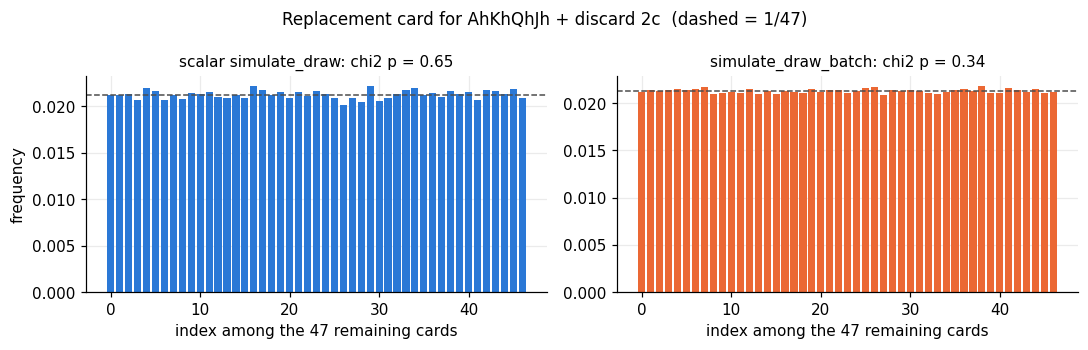

In [22]:
h = pe.parse_hand("Ah Kh Qh Jh 2c"); mask = 0b01111  # draw 1 card at position 4
deck = pe.remaining_deck(h)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (label, draws, color) in zip(axes, [
        ("scalar simulate_draw", np.array([pe.simulate_draw(h, mask, rng)[4] for _ in range(94_000)]), BLUE),
        ("simulate_draw_batch", pe.simulate_draw_batch(np.repeat(h[None], 470_000, 0), mask, rng)[:, 4], ORANGE)]):
    obs = np.array([(draws == c).sum() for c in deck])
    r = stats.chisquare(obs)
    assert obs.sum() == len(draws), "drew a card from the original hand"
    ax.bar(np.arange(47), obs / len(draws), color=color, width=0.8)
    ax.axhline(1 / 47, color="0.3", ls="--", lw=1)
    ax.set_title(f"{label}: chi2 p = {r.pvalue:.2f}", fontsize=10); ax.set_xlabel("index among the 47 remaining cards")
axes[0].set_ylabel("frequency")
fig.suptitle("Replacement card for AhKhQhJh + discard 2c  (dashed = 1/47)", fontsize=11); fig.tight_layout(); plt.show()

In [23]:
# without replacement: 2 discards -> all 1081 unordered pairs equally likely
h = pe.parse_hand("9s 9d 4c 7h 2d"); mask = 0b00111
fin = pe.simulate_draw_batch(np.repeat(h[None], 1_081_000, 0), mask, rng)
a, b = np.sort(fin[:, 3:5], axis=1).T
counts = np.bincount(a * 52 + b, minlength=52 * 52)
counts = counts[counts > 0]
print(f"distinct pairs observed: {len(counts)} (expected 1081), any equal-card pair: {(a == b).any()}")
print(f"chi-square uniformity over pairs: p = {stats.chisquare(counts).pvalue:.3f}")

distinct pairs observed: 1081 (expected 1081), any equal-card pair: False
chi-square uniformity over pairs: p = 0.126


In [24]:
rng = np.random.default_rng(4)
tests = [("Ah Kh Qh Jh 2c", 0b01111, "draw to royal"), ("Jc Jd 2h 5s 8c", 0b00011, "hold JJ"),
         ("4c 4d 9h 9s Kc", 0b01111, "hold two pair"), ("2h 7h 9h Jh Kc", 0b01111, "4-flush"),
         ("5c 6d 7h 8s Kc", 0b01111, "open-ended straight"), ("2c 4d 6h 8s Tc", 0, "discard all")]
N = 400_000
rows = []
for s, m, desc in tests:
    h = pe.parse_hand(s)
    exact = pe.exact_action_value(h, m)
    r = pe.payout_batch(pe.simulate_draw_batch(np.repeat(h[None], N, 0), m, rng))
    se = r.std(ddof=1) / np.sqrt(N); z = (r.mean() - exact) / se
    rows.append({"hand": s, "action": f"{pe.mask_to_str(m)} ({desc})", "exact EV": exact,
                 "MC mean": r.mean(), "MC s.e.": se, "z": z, "within 99% CI": abs(z) < 2.576})
mc = pd.DataFrame(rows); mc.style.format({"exact EV": "{:.5f}", "MC mean": "{:.5f}", "MC s.e.": "{:.5f}", "z": "{:+.2f}"})

,hand,action,exact EV,MC mean,MC s.e.,z,within 99% CI
0,Ah Kh Qh Jh 2c,KKKKD (draw to royal),18.55319,18.81333,0.18357,+1.42,True
1,Jc Jd 2h 5s 8c,KKDDD (hold JJ),1.53654,1.54022,0.00256,+1.44,True
2,4c 4d 9h 9s Kc,KKKKD (hold two pair),2.59574,2.59255,0.00308,-1.04,True
3,2h 7h 9h Jh Kc,KKKKD (4-flush),1.21277,1.21057,0.00370,-0.59,True
4,5c 6d 7h 8s Kc,KKKKD (open-ended straight),0.68085,0.68439,0.00238,+1.49,True
5,2c 4d 6h 8s Tc,DDDDD (discard all),0.35881,0.35574,0.00141,-2.17,True


In [25]:
# Reproducibility and speed
h = pe.parse_hand("Jc Jd 2h 5s 8c")
a = [pe.simulate_draw(h, 3, np.random.default_rng(7)).tolist() for _ in range(3)]
assert a[0] == a[1] == a[2]
r1 = pe.simulate_draw_batch(sample[:1000], 3, np.random.default_rng(7)); r2 = pe.simulate_draw_batch(sample[:1000], 3, np.random.default_rng(7))
assert (r1 == r2).all(); print("same seed -> same draws (scalar and batch)")

rng = np.random.default_rng(0); n = 50_000; t0 = time.time()
for i in range(n):
    hh = sample[i]; _, perm, sid_ = pe.canonicalize(hh)
    pe.payout(pe.simulate_draw(hh, pe.canonical_mask_to_original(3, perm), rng))
t1 = time.time()
pe.payout_batch(pe.simulate_draw_batch(sample[:n], 3, rng)); t2 = time.time()
print(f"scalar episode (canonicalize + map + draw + payout): {(t1 - t0) / n * 1e6:.1f} µs")
print(f"batch episode: {(t2 - t1) / n * 1e6:.2f} µs")

same seed -> same draws (scalar and batch)
scalar episode (canonicalize + map + draw + payout): 18.5 µs
batch episode: 1.77 µs


### 5.1 Ground truth for other tasks: exact action values

`pe.exact_action_values(hand)` returns the exact $Q^*(s,a)$ for all 32 masks by enumeration. It is a few seconds per hand, too slow for training but handy for checking the trainer (Task 2) and the heuristics (Task 3) on individual hands.

In [26]:
h = pe.parse_hand("Th Jh Qh Kh 9c")
q = pe.exact_action_values(h)
top = np.argsort(-q)[:5]
pd.DataFrame({"mask": [pe.mask_to_str(a) for a in top], "keeps": [pe.hand_to_str(h[pe.kept_positions(a)]) for a in top],
              "exact EV": q[top]})

,mask,keeps,exact EV
0,KKKKD,Th Jh Qh Kh,19.595745
1,KKKKK,Th Jh Qh Kh 9c,4.000000
2,KKKDK,Th Jh Qh 9c,0.723404
3,DKKKD,Jh Qh Kh,0.674376
4,KKKDD,Th Jh Qh,0.653099


## 6. Deduplication and the shared split

**Choices (rationale in §8):**

* **Deduplication key:** the unordered card set. Within each split we keep the first occurrence and its original card order.
* **dev** = unique card sets of the UCI *training* file (24,898). This file is biased (straight and royal flushes oversampled), so it is used only for development and tuning.
* **eval** = 50,000 card sets from the UCI *test* file, stratified by CLASS (seed 150). They exclude any card set in dev.
* **train** = all remaining unique card sets of the test file (771,352), used as starting hands for Q-learning.
* The three splits are pairwise disjoint as card sets.

In [27]:
manifest = pdata.build_splits()
splits = {k: pdata.load_split(k) for k in pdata.SPLITS}
print(json.dumps({k: {kk: vv for kk, vv in v.items() if kk != "class_counts"} for k, v in manifest["splits"].items()}, indent=1))

{
 "train": {
  "source_file": "poker-hand-testing.data",
  "n_hands": 771352,
  "n_states": 133131
 },
 "dev": {
  "source_file": "poker-hand-training-true.data",
  "n_hands": 24898,
  "n_states": 22602
 },
 "eval": {
  "source_file": "poker-hand-testing.data",
  "n_hands": 50000,
  "n_states": 41542
 }
}


In [28]:
# Integrity checks
ks = {k: pe.hand_index_batch(v["cards"]) for k, v in splits.items()}
for k in ks: assert len(np.unique(ks[k])) == len(ks[k]), f"{k} has duplicates"
for a, b in [("train", "dev"), ("train", "eval"), ("dev", "eval")]:
    assert len(np.intersect1d(ks[a], ks[b])) == 0
    print(f"{a} ∩ {b} = 0 card sets")
assert len(np.union1d(ks["train"], ks["eval"])) == len(np.setdiff1d(np.unique(keys["test file"]), keys["train file"]))
for k, v in splits.items():
    src = raw["train file" if k == "dev" else "test file"]
    assert (pdata.df_to_cards(src.iloc[v["source_row"]]) == v["cards"]).all()
    assert (pe.CATEGORY_TO_UCI[pe.hand_category_batch(v["cards"])] == v["uci_class"]).all()
    assert (pe.state_id_batch(v["cards"]) == v["state_id"]).all()
print("each split: no duplicates, cards/labels/state ids match the source rows")

train ∩ dev = 0 card sets


train ∩ eval = 0 card sets
dev ∩ eval = 0 card sets


each split: no duplicates, cards/labels/state ids match the source rows


In [29]:
dist = pd.DataFrame({k: np.bincount(v["uci_class"], minlength=10) for k, v in splits.items()}, index=pe.UCI_CLASS_NAMES)
dist["exact p"] = true_p
for k in pdata.SPLITS: dist[f"{k} p"] = dist[k] / dist[k].sum()
dist.style.format({c: "{:.4%}" for c in dist.columns if c.endswith(" p")})

,train,dev,eval,exact p,train p,dev p,eval p
nothing,386593,12441,25059,50.1177%,50.1189%,49.9679%,50.1180%
one_pair,325932,10545,21127,42.2569%,42.2546%,42.3528%,42.2540%
two_pair,36666,1202,2377,4.7539%,4.7535%,4.8277%,4.7540%
three_of_a_kind,16319,512,1058,2.1128%,2.1156%,2.0564%,2.1160%
straight,3004,93,195,0.3925%,0.3894%,0.3735%,0.3900%
flush,1539,54,100,0.1965%,0.1995%,0.2169%,0.2000%
full_house,1107,36,72,0.1441%,0.1435%,0.1446%,0.1440%
four_of_a_kind,181,6,12,0.0240%,0.0235%,0.0241%,0.0240%
straight_flush,11,5,0,0.0014%,0.0014%,0.0201%,0.0000%
royal_flush,0,4,0,0.0002%,0.0000%,0.0161%,0.0000%


Eval contains no straight or royal flushes. With 50,000 hands we expect only 0.69 straight flushes and 0.08 royal flushes, and all 4 royal-flush card sets in the test file are already in dev. Per-class results for those classes should therefore use constructed hands. They are trivial anyway, since the best action is to keep all five cards.

**State overlap.** A tabular agent can only act well on states it has seen. Splitting on card sets (not states) keeps every eval *hand* out of training while still letting eval hands share canonical states with training hands, as the proposal intends. The cell below shows how much of eval falls in states that occur among the train hands. During training the agent can also be dealt fresh random hands from the simulator.

eval: 99.35% of hands (99.32% of states) have their state in the train split
dev : 99.40% of hands (99.39% of states) have their state in the train split
train hands per state: median 6, states with 0 train hands: 1,328


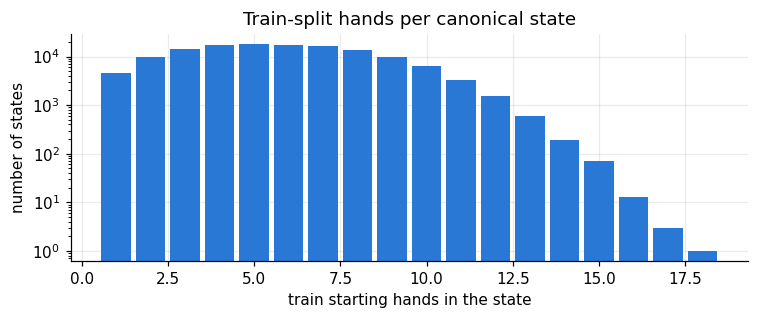

In [30]:
tr_states = np.unique(splits["train"]["state_id"])
for k in ("eval", "dev"):
    inside = np.isin(splits[k]["state_id"], tr_states)
    print(f"{k:4s}: {inside.mean():.2%} of hands ({np.isin(np.unique(splits[k]['state_id']), tr_states).mean():.2%} of states) "
          f"have their state in the train split")
per_state = np.bincount(splits["train"]["state_id"], minlength=n_states)
print(f"train hands per state: median {np.median(per_state[per_state > 0]):.0f}, "
      f"states with 0 train hands: {(per_state == 0).sum():,}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(per_state[per_state > 0], bins=np.arange(1, per_state.max() + 2) - 0.5, color=BLUE, rwidth=0.85)
ax.set_xlabel("train starting hands in the state"); ax.set_ylabel("number of states"); ax.set_yscale("log")
ax.set_title("Train-split hands per canonical state"); fig.tight_layout(); plt.show()

## 7. Interface demo: reference policies on the eval split

This is a smoke test of the agreed interfaces, using `policy(hand) -> mask`, the simulator and the reward function on eval hands. The policies are trivial and only check the plumbing. Real baselines are Task 3 and real evaluation is Task 5.

In [31]:
rng = np.random.default_rng(5)
E = splits["eval"]["cards"]
keep_all = lambda hand: pe.KEEP_ALL
random_policy = lambda hand: int(rng.integers(32))
def hold_pairs(hand):  # tiny illustration of a canonical-state policy
    r = np.asarray(hand) >> 2
    return pe.mask_from_keep([i for i in range(5) if (r == r[i]).sum() >= 2])

rows = []
for name, pol in [("keep all", keep_all), ("random", random_policy), ("hold any pair/trips/quads, else draw 5", hold_pairs)]:
    t0 = time.time()
    masks = np.array([pol(h) for h in E])
    pay = pe.payout_batch(pe.simulate_draw_batch(E, masks, rng))
    rows.append({"policy": name, "mean payout": pay.mean(), "95% CI ±": 1.96 * pay.std(ddof=1) / np.sqrt(len(pay)),
                 "seconds": time.time() - t0})
pd.DataFrame(rows).style.format({"mean payout": "{:.4f}", "95% CI ±": "{:.4f}", "seconds": "{:.2f}"})

,policy,mean payout,95% CI ±,seconds
0,keep all,0.3342,0.0078,0.09
1,random,0.3318,0.0078,0.15
2,"hold any pair/trips/quads, else draw 5",0.8437,0.0159,0.65


"keep all" lands close to the exact deal expectation from §3.1. The difference is only sampling noise and the eval split's stratified class mix.

## 8. Report material — Data processing and the poker environment

*(Also saved as `report/task1_data_environment.md`.)*

### Data processing

**Source and validation.** We use the UCI Poker Hand dataset (Cattral & Oppacher, 2007), which comes as a 25,010-row "training" file and a 1,000,000-row "testing" file. Each row lists five cards as (suit S ∈ {1..4}, rank C ∈ {1..13}, with 1 = Ace) plus a hand label CLASS ∈ {0..9}. Both files have no missing values, every attribute is in range, and no hand contains the same card twice. Chi-square tests do not reject uniform suits or ranks, either pooled over the five slots or slot by slot (all p > 0.01). Our hand evaluator reproduces all 1,025,010 CLASS labels exactly.

**Representativeness.** We computed exact class probabilities by enumerating all C(52,5) = 2,598,960 hands. The 1M-row file matches a uniform deal (class goodness-of-fit χ² = 1.66, p = 0.98; e.g. one pair 42.25% observed vs 42.26% exact). The 25,010-row file does not (p = 0.024): it contains 5 straight flushes and 5 royal flushes, which is 14.4× and 130× their natural rates (the UCI documentation gives 14.43× and 129.82×). We therefore draw all training and evaluation start hands from the 1M-row file and use the smaller file only for development and tuning.

**Deduplication.** Records are ordered: the same five cards in a different order are a different row. A discard decision depends only on the card set, so we deduplicate on the unordered set, using a combinatorial index in 0..2,598,959. Only 2,128 rows of the 1M-row file are identical, but 170,799 rows repeat a card set that appeared earlier, leaving 829,201 unique sets. That is close to the ≈830,100 expected if 10⁶ hands are sampled with replacement from 2.6M sets. The smaller file has 112 repeated sets (24,898 unique), and 7,849 card sets appear in both files.

**Split.** All three splits are pairwise disjoint as card sets. Within a split we keep the first occurrence of each set, with its original card order.

| Split | Source | Hands | Canonical states | Use |
|---|---|---:|---:|---|
| train | 1M-row file, minus dev and eval | 771,352 | 133,131 | start hands for Q-learning |
| dev | 25,010-row file, deduplicated | 24,898 | 22,602 | debugging, tuning |
| eval | 1M-row file, minus dev, 50,000 sampled stratified by CLASS (seed 150) | 50,000 | 41,542 | held-out evaluation |

The splits are stored as `data/splits/{train,dev,eval}.npz`. Each file holds `cards`, `uci_class`, `state_id` and `source_row`, and `manifest.json` records the counts. The eval split has no straight or royal flushes: we would expect only 0.7 and 0.08 of them, and all four royal-flush card sets are already in dev. Per-class results for those classes therefore use constructed hands, where the optimal play is trivially to keep all five cards. Because the split is by card set and not by state, 99.35% of eval hands fall into a canonical state that also occurs in train. This is intended: a tabular agent can only act well on states it has seen, and held-out *hands* still give an unbiased estimate of mean payout.

### Poker environment

**Encoding.** A card is an integer `4·rank + suit`, with rank 0..12 = 2..A and suit 0..3 = ♥♠♦♣, the UCI suit order. A hand is five cards in their dealt order, and an action is a 5-bit mask where bit *i* = 1 means "keep the card in position *i*". That gives 32 actions, from 0 (draw five) to 31 (stand pat).

**Hand scoring.** The evaluator treats the ace as high (T-J-Q-K-A) or low (A-2-3-4-5) in straights and allows no wrap-arounds. It splits one pair into a low pair and "jacks or better" because only the latter pays. We run a vectorized evaluator once over all 2,598,960 hands to fill a lookup table, so scoring a hand costs one index computation and one table read. We verified the evaluator three ways: (i) its category counts over all hands equal the textbook values (e.g. 1,098,240 one pairs, 36 straight flushes, 4 royal flushes); (ii) it agrees with an independent reference implementation on 300,000 random hands; and (iii) it reproduces every UCI label. Rewards come from `payout(final_hand, paytable)`. The main paytable is 9/6 Jacks-or-Better: pair of J+ = 1, two pair = 2, three of a kind = 3, straight = 4, flush = 6, full house = 9, four of a kind = 25, straight flush = 50, royal flush = 800.

**Canonicalization.** Reordering cards or permuting suits does not change any action's payout distribution. For each of the 24 suit permutations we relabel the hand and sort its cards by rank and then suit. The canonical form is the lexicographically smallest result. Enumeration gives **134,459** canonical states, a 19.3× reduction; each state contains 4, 12 or 24 hands. The 1M-row file covers 99.3% of the states. The minimizing permutation for every hand is precomputed, so canonicalizing a hand takes about 5 µs. The agent picks its mask on the canonical hand, and the environment returns `perm`, where `perm[j]` is the original position of canonical card *j*. The mask is mapped back by moving bit *j* to bit `perm[j]`. We verified the mapping by exact enumeration: for 600 random (hand, mask) pairs, the expected payout of the mapped action on the original hand equals the expected payout on the canonical hand to machine precision. Ignoring `perm` gives wrong values; for example, a pair of kings is worth 1.54 when kept but 0.16 when the wrong two cards are kept.

**Draw simulator.** `simulate_draw(hand, mask, rng)` keeps the masked cards in their positions and fills each discarded position with a card drawn uniformly **without replacement** from the 47 cards not in the original hand, so discarded cards never return. It uses a partial Fisher–Yates shuffle, and a vectorized batch version is provided for evaluation. In 120,000 random episodes, kept cards never changed, final hands never contained duplicates, and no replacement came from the original hand. Single-card replacements are uniform over the 47 cards (χ² p = 0.65 scalar, 0.34 batch), and two-card draws are uniform over all C(47,2) = 1,081 pairs (p = 0.13). Monte Carlo means (400,000 draws each) match exact expected payouts, computed by enumerating every possible draw, within the 99% confidence interval for six representative hand/action pairs. Examples: holding JJ is worth 1.537, holding two pair 2.596, and drawing to a four-card royal 18.55. One episode (canonicalize, map, draw, score) takes about 18 µs in pure Python and about 2 µs per hand in batch mode.

**Assumptions.** One draw round with no betting or opponents, a fair 52-card deck, and uniform draws. The final hand depends only on (initial hand, mask, random draw), so Q(s, a) equals the expected payout.
